# 📧 Spam E-posta Tespiti — Yapay Zeka Ödevi

**Ödevin istediği:**
1. Spam / normal (ham) e-postalardan oluşan bir veri seti bulmak
2. Bu veri setini **en az 3 makine öğrenmesi algoritmasıyla** eğitmek
3. Test işlemlerini yapıp **en iyi sonucu veren algoritmayı** belirlemek
4. **Karışıklık (Confusion) Matrisi** ve **ROC eğrisi** ne işe yarar, açıklamak

Bu notebook hem ödevi yapıyor hem de her adımı **neden** yaptığımızı anlatıyor. Hücreleri yukarıdan aşağıya sırayla çalıştır (her hücrede `Shift + Enter`, ya da üst menüden **Çalışma zamanı → Tümünü çalıştır**).

---

## 🧠 Önce büyük resim: Makine öğrenmesi burada ne yapıyor?

Bilgisayara "şu kelimeler geçerse spamdir" diye **kural yazmıyoruz**. Bunun yerine ona binlerce **etiketli örnek** veriyoruz:

| E-posta | Etiket |
|---|---|
| "Kazandınız! Hemen tıklayın, ücretsiz..." | spam |
| "Yarınki toplantı saat 10'da" | ham (normal) |

Model bu örneklerden **kalıpları kendisi öğrenir**. Buna **denetimli öğrenme (supervised learning)** denir; çünkü doğru cevapları (etiketleri) biz veriyoruz. Çıktı iki sınıftan biri olduğu için de bu bir **ikili sınıflandırma (binary classification)** problemidir.

**İzleyeceğimiz yol:**
```
Veriyi yükle → İncele → Temizle → Eğitim/Test diye ikiye böl → Metni sayıya çevir
→ 4 modeli eğit → Test et → Metrikleri, karışıklık matrisini, ROC eğrisini karşılaştır → En iyisini seç
```

## 1️⃣ Kütüphaneleri yükleme

- **pandas**: Tablo (Excel gibi) verilerle çalışmak için
- **numpy**: Sayısal işlemler
- **matplotlib / seaborn**: Grafik çizmek için
- **scikit-learn (sklearn)**: Makine öğrenmesi algoritmalarının ve ölçüm araçlarının bulunduğu ana kütüphane

Colab'da bunların hepsi hazır yüklü gelir, sadece `import` ediyoruz.

In [1]:
import re, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")
RASTGELE = 42   # Sonuçlar her çalıştırmada aynı çıksın diye sabit bir "tohum" sayısı
print("Kütüphaneler yüklendi ✅")

Kütüphaneler yüklendi ✅


## 2️⃣ Veri setini bulma ve indirme

Kullandığımız veri seti: **Enron-Spam Veri Seti**

- **Enron**, 2001'de iflas eden büyük bir Amerikan enerji şirketi. Soruşturma sırasında çalışanlarının **gerçek e-postaları** kamuya açıldı.
- Araştırmacılar (Metsis, Androutsopoulos ve Paliouras, 2006) bu normal e-postaları gerçek spam e-postalarla birleştirip etiketlediler. Spam filtreleme çalışmalarında en çok kullanılan veri setlerinden biridir.
- Toplam **33.716 e-posta**, her birinde *Konu (Subject)*, *Mesaj (Message)* ve *etiket (spam/ham)* var.
- Kaynak: https://github.com/MWiechmann/enron_spam_data (CSV hâline getirilmiş sürüm)

> 💡 İnternette sık görülen "SMS Spam Collection" veri seti **SMS** mesajlarıdır, e-posta değildir. Ödev "mail" dediği için gerçek e-postalardan oluşan Enron'u seçtik.

Aşağıdaki hücre dosyayı doğrudan internetten indirir; elle bir şey yüklemene gerek yok.

In [2]:
URL = "https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip"
urllib.request.urlretrieve(URL, "enron_spam_data.zip")
with zipfile.ZipFile("enron_spam_data.zip") as z:
    z.extractall(".")

df = pd.read_csv("enron_spam_data.csv")
print("Veri boyutu (satır, sütun):", df.shape)
df.head()

Veri boyutu (satır, sütun): (33716, 5)


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


## 3️⃣ Veriyi tanıma (Keşifsel Veri Analizi)

Modeli eğitmeden önce verinin neye benzediğine bakmalıyız:
- Kaç spam, kaç normal e-posta var? (**Sınıf dengesi**)
- Boş (eksik) hücre var mı?

**Sınıf dengesi neden önemli?** Diyelim ki verinin %95'i normal, %5'i spam olsun. O zaman hiçbir şey öğrenmeyip her şeye "normal" diyen bir model bile %95 doğruluk alır! Bu yüzden dengeye bakmak şart.

Etiket dağılımı:
Spam/Ham
spam    17171
ham     16545
Name: count, dtype: int64

Eksik değer sayıları:
Message ID      0
Subject       289
Message       371
Spam/Ham        0
Date            0
dtype: int64


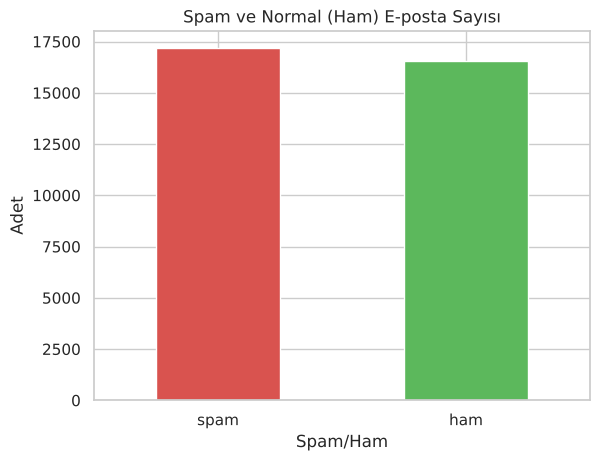

In [3]:
print("Etiket dağılımı:")
print(df["Spam/Ham"].value_counts())
print("\nEksik değer sayıları:")
print(df.isna().sum())

ax = df["Spam/Ham"].value_counts().plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0)
ax.set_title("Spam ve Normal (Ham) E-posta Sayısı"); ax.set_ylabel("Adet")
plt.show()

**Yorum:** Veri neredeyse yarı yarıya dengeli (~17 bin spam, ~16,5 bin ham). Bu güzel, demek ki doğruluk (accuracy) metriği burada yanıltıcı olmaz. Birkaç yüz e-postanın konusu ya da gövdesi boş; bunları bir sonraki adımda düzelteceğiz.

Bir spam ve bir normal örneğe bakalım:

In [4]:
print("=== SPAM ÖRNEĞİ ===")
print(df[df["Spam/Ham"] == "spam"].iloc[3]["Message"][:500])
print("\n=== NORMAL (HAM) ÖRNEĞİ ===")
print(df[df["Spam/Ham"] == "ham"].iloc[3]["Message"][:500])

=== SPAM ÖRNEĞİ ===
dear partner ,
we are a team of government officials that belong to an eight - man committee in the presidential cabinet as well as the senate .
at the moment , we will be requiring your assistance in a matter that involves investment of monies , which we intend to transfer to your account , upon clarification and a workable agreement reached in consummating the project with you . based on a recommendation from an associate concerning your integrity , loyalty and understanding , we deemed it nec

=== NORMAL (HAM) ÖRNEĞİ ===
fyi - see note below - already done .
stella
- - - - - - - - - - - - - - - - - - - - - - forwarded by stella l morris / hou / ect on 12 / 14 / 99 10 : 18
am - - - - - - - - - - - - - - - - - - - - - - - - - - -
from : sherlyn schumack on 12 / 14 / 99 10 : 06 am
to : stella l morris / hou / ect @ ect
cc : howard b camp / hou / ect @ ect
subject : re : issue
stella ,
this has already been taken care of . you did this for me yesterday .
thanks .
how

## 4️⃣ Veri ön işleme (Temizleme)

Bilgisayar ham metni olduğu gibi anlayamaz, önce düzenlememiz gerekir:

1. **Eksik değerler:** Boş konu/mesaj hücrelerini boş metinle (`""`) dolduruyoruz.
2. **Konu + Mesajı birleştirme:** Spam ipuçları çoğu zaman konu satırındadır ("FREE!!!", "You won"), bu yüzden ikisini tek metin yapıyoruz.
3. **Küçük harfe çevirme:** "Free" ile "free" aynı kelime sayılsın.
4. **Sayıları, URL'leri ve noktalama işaretlerini sadeleştirme:** Her farklı link ya da sayı ayrı bir kelime gibi görülmesin diye hepsini ortak bir işarete dönüştürüyoruz (`url`, `sayi`).
5. **Etiketi sayıya çevirme:** Modeller sayı ister → `spam = 1`, `ham = 0`.

In [5]:
df["Subject"] = df["Subject"].fillna("")
df["Message"] = df["Message"].fillna("")

def temizle(metin):
    metin = metin.lower()                                   # küçük harf
    metin = re.sub(r"http\S+|www\.\S+", " url ", metin)     # linkler -> 'url'
    metin = re.sub(r"\S+@\S+", " email ", metin)            # e-posta adresleri -> 'email'
    metin = re.sub(r"\d+", " sayi ", metin)                 # sayılar -> 'sayi'
    metin = re.sub(r"[^a-z\s]", " ", metin)                 # harf dışı her şeyi sil
    return re.sub(r"\s+", " ", metin).strip()               # fazla boşlukları sil

df["metin"] = (df["Subject"] + " " + df["Message"]).apply(temizle)
df["etiket"] = (df["Spam/Ham"] == "spam").astype(int)      # spam=1, ham=0

df[["metin", "etiket"]].head()

,metin,etiket
0,christmas tree farm pictures,0
1,vastar resources inc gary production from the ...,0
2,calpine daily gas nomination calpine daily gas...,0
3,re issue fyi see note below already done stell...,0
4,meter sayi nov allocation fyi forwarded by lau...,0


## 5️⃣ Eğitim ve Test kümesine ayırma

**Çok önemli bir kavram!** Modeli **gördüğü verilerle** test edersek, ezberleyip ezberlemediğini anlayamayız. Bir öğrenciye sınavda, çalıştığı soruların aynısını sormak gibi olur.

Bu yüzden veriyi ikiye bölüyoruz:
- **Eğitim kümesi (%80):** Model bunlardan öğrenir.
- **Test kümesi (%20):** Model bunları **hiç görmez**; en sonda gerçek başarıyı ölçmek için kullanılır.

`stratify=y` parametresi, iki kümede de spam/ham oranının aynı kalmasını sağlar.

> ⚠️ **Ezberleme (overfitting):** Model eğitim verisinde mükemmel, yeni veride kötü çalışıyorsa ezberlemiş demektir. Ayrı test kümesi bunu yakalamamızı sağlar.

In [6]:
X = df["metin"]
y = df["etiket"]

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RASTGELE, stratify=y)

print("Eğitim kümesi:", len(X_egitim), "e-posta")
print("Test kümesi  :", len(X_test), "e-posta")

Eğitim kümesi: 26972 e-posta
Test kümesi  : 6744 e-posta


## 6️⃣ Metni sayıya çevirme: TF-IDF

Makine öğrenmesi algoritmaları kelimelerle değil **sayılarla** çalışır. Her e-postayı bir sayı listesine (vektöre) çevirmemiz gerekiyor. Bunun için **TF-IDF** kullanıyoruz:

- **TF (Term Frequency — Terim Sıklığı):** Bir kelime **bu e-postada** kaç kez geçiyor? Çok geçiyorsa önemlidir.
- **IDF (Inverse Document Frequency — Ters Belge Sıklığı):** Bu kelime **bütün e-postaların** kaçında geçiyor? Her yerde geçen kelimeler ("the", "and", "is") ayırt edici değildir, puanları düşürülür. Nadir ama anlamlı kelimeler ("viagra", "lottery") yüksek puan alır.

**TF-IDF = TF × IDF**  →  *"Bu e-postada sık geçen ama genelde nadir olan kelimeler önemlidir."*

Sonuçta her e-posta, örneğin 30.000 sütunlu bir satıra dönüşür; her sütun bir kelimenin TF-IDF puanıdır.

Kullandığımız ayarlar:
- `stop_words="english"`: "the, is, at" gibi anlamsız sık kelimeleri atar
- `max_features=30000`: En önemli 30.000 kelimeyi tutar
- `ngram_range=(1,2)`: Tek kelimelerin yanında **ikili kelime gruplarına** da bakar ("click here", "free money")
- `min_df=2`: Sadece 1 e-postada geçen kelimeleri yok sayar (genelde yazım hatasıdır)

> 💡 **Önemli:** TF-IDF'i sadece **eğitim verisinden** öğreniyoruz (`fit`), test verisine sadece **uyguluyoruz** (`transform`). Yoksa test verisi hakkında bilgi "sızdırmış" oluruz (**data leakage**).

In [7]:
tfidf = TfidfVectorizer(stop_words="english", max_features=30000,
                        ngram_range=(1, 2), min_df=2, sublinear_tf=True)

X_egitim_vek = tfidf.fit_transform(X_egitim)   # eğitimden öğren + dönüştür
X_test_vek   = tfidf.transform(X_test)         # sadece dönüştür

print("Eğitim matrisi boyutu:", X_egitim_vek.shape)
print("Test matrisi boyutu  :", X_test_vek.shape)

Eğitim matrisi boyutu: (26972, 30000)
Test matrisi boyutu  : (6744, 30000)


## 7️⃣ Kullanacağımız 4 algoritma

Ödev en az 3 istiyor; karşılaştırmayı zenginleştirmek için 4 tane kullanıyoruz.

### 🅰️ Naive Bayes (Multinomial)
Olasılığa dayanır (**Bayes Teoremi**). Her kelimenin spam e-postalarda ve normal e-postalarda ne sıklıkla geçtiğini hesaplar. Yeni bir e-posta gelince: *"Bu kelimeler bir arada geçiyorsa spam olma olasılığı nedir?"* diye sorar.
"Naive" (saf) denmesinin sebebi, kelimelerin birbirinden **bağımsız** olduğunu varsaymasıdır (gerçekte değillerdir ama yine de çok iyi çalışır). Metin sınıflandırmanın klasik, çok hızlı yöntemidir.

### 🅱️ Lojistik Regresyon (Logistic Regression)
İsmi "regresyon" olsa da **sınıflandırma** yapar. Her kelimeye bir **ağırlık** verir (spam kelimeleri pozitif, normal kelimeler negatif). Ağırlıkları toplar ve **sigmoid** fonksiyonuyla 0 ile 1 arasında bir **olasılığa** çevirir. 0,5'ten büyükse spam der.

### 🅲 Destek Vektör Makinesi (SVM — Linear SVC)
Verileri çok boyutlu bir uzayda noktalar olarak düşünür ve spam ile normal e-postaları ayıran **en geniş boşluklu (marjlı) çizgiyi/düzlemi** bulur. İki sınıf arasındaki "güvenlik şeridini" olabildiğince geniş tutmaya çalışır. Yüksek boyutlu verilerde (metin gibi) çok başarılıdır.

### 🅳 Rastgele Orman (Random Forest)
Çok sayıda **karar ağacından** oluşur. Her ağaç verinin rastgele bir parçasıyla eğitilir ve "evet/hayır" sorularıyla karar verir ("'free' kelimesi var mı? → evet → 'click' var mı? → ..."). Sonunda ağaçlar **oylama** yapar, çoğunluk kazanır. Tek ağaca göre çok daha az ezberler.

In [8]:
modeller = {
    "Naive Bayes":         MultinomialNB(alpha=0.1),
    "Lojistik Regresyon":  LogisticRegression(max_iter=1000, C=10),
    "SVM (Linear SVC)":    LinearSVC(C=1.0),
    "Random Forest":       RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RASTGELE),
}

## 8️⃣ Başarı ölçütleri (metrikler) — önce kavramlar

Test kümesindeki her e-posta için modelin tahmini 4 durumdan birine düşer. **Spam = Pozitif** kabul edelim:

| | **Model: Spam dedi** | **Model: Normal dedi** |
|---|---|---|
| **Gerçekte Spam** | ✅ **TP** (Doğru Pozitif) | ❌ **FN** (Yanlış Negatif) — *spam kaçtı, gelen kutuna düştü* |
| **Gerçekte Normal** | ❌ **FP** (Yanlış Pozitif) — *önemli mailin spam klasörüne gitti!* | ✅ **TN** (Doğru Negatif) |

Bu dört sayıdan şu metrikler hesaplanır:

- **Doğruluk (Accuracy)** = (TP+TN) / Toplam → *Tüm tahminlerin yüzde kaçı doğru?*
- **Kesinlik (Precision)** = TP / (TP+FP) → *Model "spam" dediğinde ne kadar haklı?* Yüksekse önemli mailler spam'e düşmez.
- **Duyarlılık (Recall)** = TP / (TP+FN) → *Gerçek spamlerin yüzde kaçını yakaladı?* Yüksekse gelen kutun temiz kalır.
- **F1-Skoru** = Precision ve Recall'un **harmonik ortalaması** → İkisini tek bir sayıda dengeler. Biri çok düşükse F1 de düşer.

> 📌 Spam filtresinde **FP daha kötü bir hatadır**: Bir spam'in gelen kutusuna düşmesi can sıkar ama iş görüşmesi davetinin spam klasörüne gitmesi gerçek bir kayıptır. Bu yüzden Precision'a ayrıca dikkat ederiz.

## 9️⃣ Modelleri eğitme ve test etme

Her model için:
1. `fit()` → Eğitim verisiyle **öğrenir**
2. `predict()` → Test verisini **tahmin eder**
3. Tahminleri gerçek etiketlerle karşılaştırıp metrikleri hesaplarız
4. ROC eğrisi için her e-postaya bir **"spam olma puanı"** da alırız (aşağıda açıklanıyor)

In [9]:
sonuclar = []
puanlar = {}      # ROC eğrisi için her modelin "spam puanları"
tahminler = {}    # Karışıklık matrisi için tahminler

for ad, model in modeller.items():
    t0 = time.time()
    model.fit(X_egitim_vek, y_egitim)              # 1) ÖĞREN
    tahmin = model.predict(X_test_vek)             # 2) TAHMİN ET
    sure = time.time() - t0

    # ROC için sürekli bir puan lazım:
    # çoğu model olasılık verir (predict_proba); SVM ise sınıra uzaklık verir (decision_function)
    if hasattr(model, "predict_proba"):
        puan = model.predict_proba(X_test_vek)[:, 1]
    else:
        puan = model.decision_function(X_test_vek)

    tahminler[ad], puanlar[ad] = tahmin, puan
    sonuclar.append({
        "Model": ad,
        "Accuracy":  accuracy_score(y_test, tahmin),
        "Precision": precision_score(y_test, tahmin),
        "Recall":    recall_score(y_test, tahmin),
        "F1":        f1_score(y_test, tahmin),
        "ROC-AUC":   roc_auc_score(y_test, puan),
        "Süre (sn)": sure,
    })
    print(f"{ad:20s} eğitildi  ({sure:.1f} sn)")

sonuc_tablosu = pd.DataFrame(sonuclar).set_index("Model").sort_values("F1", ascending=False)
sonuc_tablosu.style.format("{:.4f}").background_gradient(cmap="Greens",
    subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])

Naive Bayes          eğitildi  (0.0 sn)


Lojistik Regresyon   eğitildi  (0.3 sn)
SVM (Linear SVC)     eğitildi  (0.2 sn)


Random Forest        eğitildi  (16.0 sn)


,Accuracy,Precision,Recall,F1,ROC-AUC,Süre (sn)
Model,,,,,,
SVM (Linear SVC),0.9941,0.9916,0.9968,0.9942,0.9996,0.1725
Lojistik Regresyon,0.9935,0.9896,0.9977,0.9936,0.9995,0.3220
Naive Bayes,0.9905,0.9898,0.9916,0.9907,0.9992,0.0181
Random Forest,0.9872,0.9830,0.9921,0.9875,0.9987,16.0203


Her model için ayrıntılı rapor (sınıf bazında precision / recall / F1):

In [10]:
for ad in modeller:
    print("=" * 55, f"\n{ad}\n" + "=" * 55)
    print(classification_report(y_test, tahminler[ad], target_names=["Normal (ham)", "Spam"], digits=4))

Naive Bayes
              precision    recall  f1-score   support

Normal (ham)     0.9912    0.9894    0.9903      3309
        Spam     0.9898    0.9916    0.9907      3435

    accuracy                         0.9905      6744
   macro avg     0.9905    0.9905    0.9905      6744
weighted avg     0.9905    0.9905    0.9905      6744

Lojistik Regresyon
              precision    recall  f1-score   support

Normal (ham)     0.9976    0.9891    0.9933      3309
        Spam     0.9896    0.9977    0.9936      3435

    accuracy                         0.9935      6744
   macro avg     0.9936    0.9934    0.9935      6744
weighted avg     0.9935    0.9935    0.9935      6744

SVM (Linear SVC)
              precision    recall  f1-score   support

Normal (ham)     0.9967    0.9912    0.9939      3309
        Spam     0.9916    0.9968    0.9942      3435

    accuracy                         0.9941      6744
   macro avg     0.9941    0.9940    0.9941      6744
weighted avg     0.9941   

## 🔟 Karışıklık Matrisi (Confusion Matrix) — Ne işe yarar?

**Karışıklık matrisi, modelin hangi sınıfları birbirine karıştırdığını gösteren 2×2'lik tablodur.** Yukarıda gördüğümüz TP, TN, FP, FN sayılarının ta kendisidir.

**Neden önemli?**
- **Doğruluk tek başına yetmez.** %98 doğruluk diyen bir model, hataların hepsini "önemli mailleri spam sanmak" şeklinde yapıyor olabilir. Karışıklık matrisi **hatanın türünü** gösterir.
- Hangi tür hatanın daha çok olduğunu görüp modeli ona göre ayarlayabiliriz.
- Precision, Recall, F1 gibi bütün metrikler bu tablodan hesaplanır.

**Nasıl okunur?** Köşegen (sol üst → sağ alt) **doğru** tahminlerdir; bu sayılar büyük olmalı. Köşegen dışı **hatalardır**; bunlar küçük olmalı.

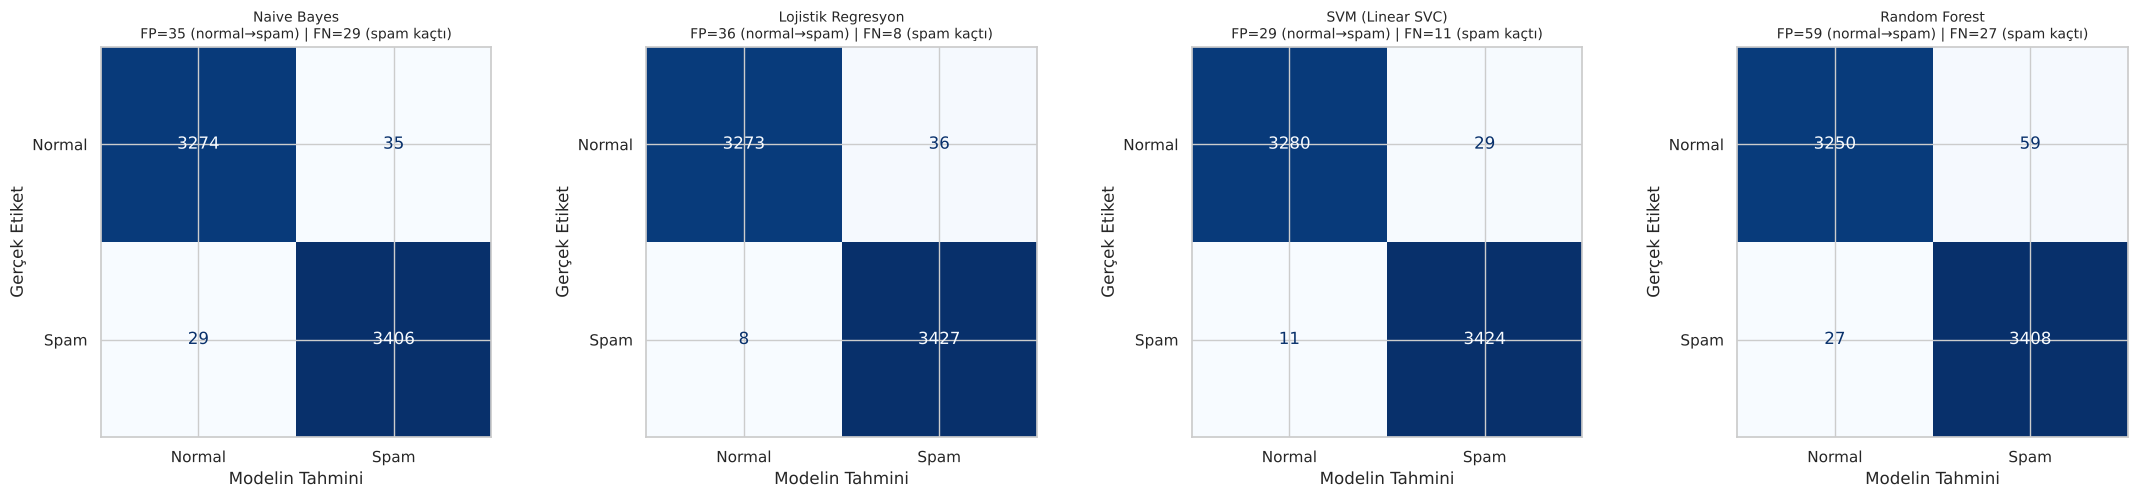

In [11]:
fig, eksenler = plt.subplots(1, 4, figsize=(22, 5))
for ax, ad in zip(eksenler, modeller):
    cm = confusion_matrix(y_test, tahminler[ad])
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Spam"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{ad}\nFP={fp} (normal→spam) | FN={fn} (spam kaçtı)", fontsize=10)
    ax.set_xlabel("Modelin Tahmini"); ax.set_ylabel("Gerçek Etiket")
plt.tight_layout(); plt.show()

**Yorum:** Her matriste sağ üst hücre **FP** (normal e-postayı yanlışlıkla spam sanmış), sol alt hücre **FN** (spam'i kaçırmış) sayısıdır. Bu sayıların en küçük olduğu model en az hata yapan modeldir.

## 1️⃣1️⃣ ROC Eğrisi — Ne işe yarar?

Modeller aslında doğrudan "spam/normal" demez; önce her e-postaya bir **puan** verir (ör. "%73 spam"). Sonra bir **eşik değeri** (genelde 0,5) ile karar verir: puan eşikten büyükse spam.

**Sorun:** Eşik 0,5 olmak zorunda değil!
- Eşiği **düşürürsek** (0,2) → daha çok spam yakalarız ama daha çok normal maili de yanlışlıkla spam sayarız.
- Eşiği **yükseltirsek** (0,9) → az hata yaparız ama bazı spamleri kaçırırız.

**ROC eğrisi (Receiver Operating Characteristic), olası BÜTÜN eşik değerlerini tek grafikte gösterir:**
- **Y ekseni — Doğru Pozitif Oranı (TPR = Recall):** Spamlerin yüzde kaçını yakaladık?
- **X ekseni — Yanlış Pozitif Oranı (FPR = FP / (FP+TN)):** Normal maillerin yüzde kaçını yanlışlıkla spam saydık?

**Nasıl okunur?**
- **Sol üst köşe (0, 1)** mükemmel modeldir: hiç yanlış alarm yok, bütün spamler yakalandı.
- **Çapraz kesikli çizgi** yazı-tura atan rastgele bir modeldir.
- Eğri sol üst köşeye ne kadar yakınsa model o kadar iyidir.

**AUC (Area Under Curve — Eğri Altında Kalan Alan):** ROC eğrisinin altındaki alan, **0,5 ile 1 arasında tek bir sayı**:
- **1,0** → kusursuz  •  **0,9+** → mükemmel  •  **0,5** → rastgele tahmin
- Yorumu: *Rastgele bir spam ve rastgele bir normal mail seçtiğimizde, modelin spam'e daha yüksek puan verme olasılığı.*

**Neden faydalı?** Modelleri eşikten bağımsız olarak karşılaştırır ve uygulamamız için doğru eşiği seçmemize yardım eder (ör. "yanlış alarm oranı %1'i geçmesin, o şartla en çok spam'i yakalayan eşik hangisi?").

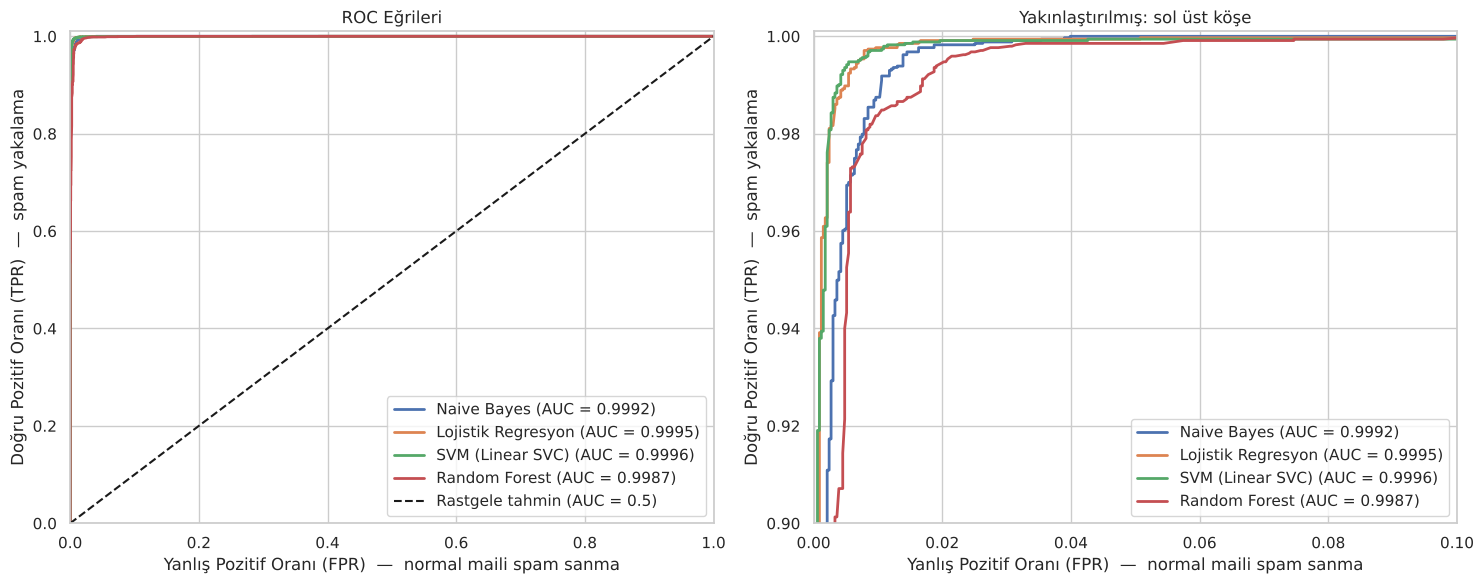

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
for ad in modeller:
    fpr, tpr, _ = roc_curve(y_test, puanlar[ad])
    auc = roc_auc_score(y_test, puanlar[ad])
    for ax in (ax1, ax2):
        ax.plot(fpr, tpr, lw=2, label=f"{ad} (AUC = {auc:.4f})")

ax1.plot([0, 1], [0, 1], "k--", label="Rastgele tahmin (AUC = 0.5)")
ax1.set_title("ROC Eğrileri"); ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.01)

# Modeller çok iyi olduğu için eğriler sol üstte üst üste biniyor; o köşeyi büyütelim
ax2.set_title("Yakınlaştırılmış: sol üst köşe")
ax2.set_xlim(0, 0.10); ax2.set_ylim(0.90, 1.001)

for ax in (ax1, ax2):
    ax.set_xlabel("Yanlış Pozitif Oranı (FPR)  —  normal maili spam sanma")
    ax.set_ylabel("Doğru Pozitif Oranı (TPR)  —  spam yakalama")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 1️⃣2️⃣ Çapraz Doğrulama (Cross-Validation) — Sonuç şans eseri mi?

Tek bir eğitim/test bölmesi şanslı ya da şanssız denk gelmiş olabilir. **5-katlı çapraz doğrulama** ile bunu kontrol ediyoruz:

1. Eğitim verisini 5 eşit parçaya böl
2. 4 parçayla eğit, kalan 1 parçayla test et
3. Bunu her parça bir kez test olacak şekilde **5 kez** tekrarla
4. 5 sonucun **ortalamasını** ve **standart sapmasını** al

Ortalama yüksek ve standart sapma küçükse model **kararlı ve güvenilirdir**.

> 💡 TF-IDF'i `make_pipeline` ile modelle birleştiriyoruz ki her katmanda TF-IDF sadece o katmanın eğitim kısmından öğrensin (veri sızıntısı olmasın).
>
> ⏳ Bu hücre birkaç dakika sürebilir (Random Forest en yavaşı).

Naive Bayes          F1 = 0.9870 ± 0.0011   katlar: [0.988  0.9864 0.9853 0.9876 0.9878]


Lojistik Regresyon   F1 = 0.9904 ± 0.0010   katlar: [0.9899 0.989  0.9898 0.9915 0.9917]


SVM (Linear SVC)     F1 = 0.9911 ± 0.0011   katlar: [0.9906 0.9908 0.9895 0.9926 0.9918]


Random Forest        F1 = 0.9836 ± 0.0011   katlar: [0.9839 0.9834 0.9817 0.984  0.9851]


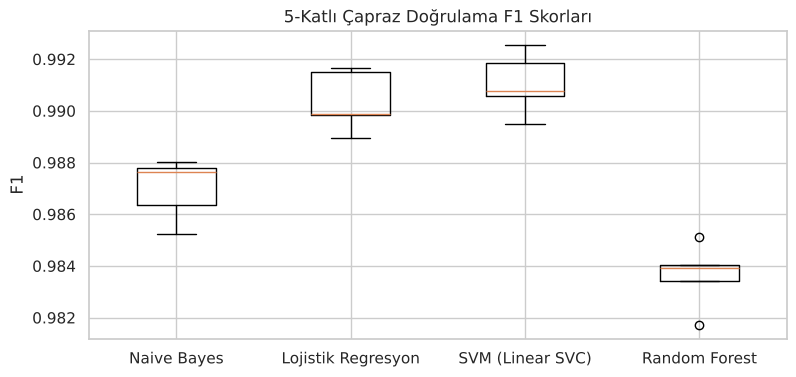

In [13]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RASTGELE)
cv_sonuc = {}
for ad, model in modeller.items():
    boru = make_pipeline(
        TfidfVectorizer(stop_words="english", max_features=30000,
                        ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        model)
    skorlar = cross_val_score(boru, X_egitim, y_egitim, cv=kfold, scoring="f1", n_jobs=-1)
    cv_sonuc[ad] = skorlar
    print(f"{ad:20s} F1 = {skorlar.mean():.4f} ± {skorlar.std():.4f}   katlar: {np.round(skorlar, 4)}")

plt.figure(figsize=(9, 4))
plt.boxplot(list(cv_sonuc.values()))
plt.xticks(range(1, len(cv_sonuc) + 1), list(cv_sonuc.keys()))
plt.title("5-Katlı Çapraz Doğrulama F1 Skorları"); plt.ylabel("F1")
plt.show()

## 1️⃣3️⃣ Sonuçların karşılaştırılması ve en iyi modelin seçilmesi

,Accuracy,Precision,Recall,F1,ROC-AUC,Süre (sn),CV F1 (ort.),CV F1 (std)
Model,,,,,,,,
SVM (Linear SVC),0.9941,0.9916,0.9968,0.9942,0.9996,0.1725,0.9911,0.0011
Lojistik Regresyon,0.9935,0.9896,0.9977,0.9936,0.9995,0.3220,0.9904,0.0010
Naive Bayes,0.9905,0.9898,0.9916,0.9907,0.9992,0.0181,0.9870,0.0011
Random Forest,0.9872,0.9830,0.9921,0.9875,0.9987,16.0203,0.9836,0.0011


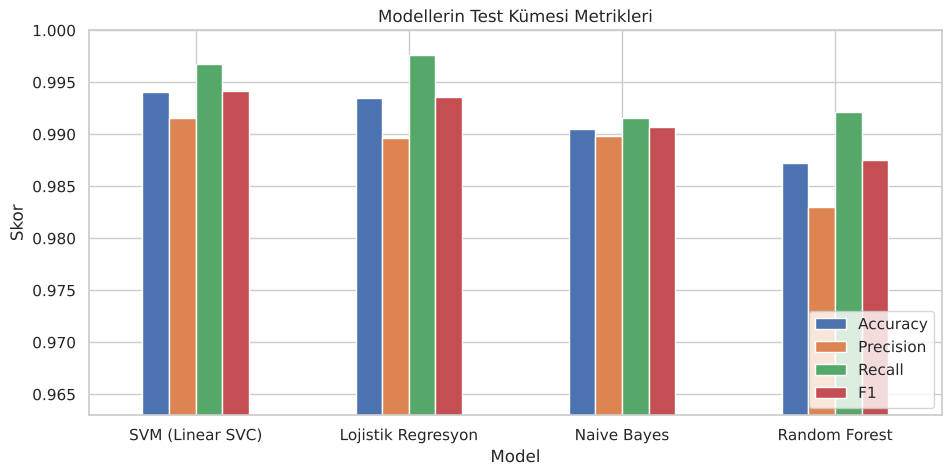


🏆 EN İYİ MODEL: SVM (Linear SVC)
   Test F1 = 0.9942 | Accuracy = 0.9941 | ROC-AUC = 0.9996 | CV F1 = 0.9911


In [14]:
tablo = sonuc_tablosu.copy()
tablo["CV F1 (ort.)"] = [cv_sonuc[m].mean() for m in tablo.index]
tablo["CV F1 (std)"]  = [cv_sonuc[m].std()  for m in tablo.index]
display(tablo.style.format("{:.4f}").highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV F1 (ort.)"], color="#b6e3b6"))

tablo[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 5), rot=0)
plt.ylim(tablo[["Accuracy", "Precision", "Recall", "F1"]].values.min() - 0.02, 1.0)
plt.title("Modellerin Test Kümesi Metrikleri"); plt.ylabel("Skor"); plt.legend(loc="lower right")
plt.show()

en_iyi = tablo["F1"].idxmax()
print(f"\n🏆 EN İYİ MODEL: {en_iyi}")
print(f"   Test F1 = {tablo.loc[en_iyi, 'F1']:.4f} | Accuracy = {tablo.loc[en_iyi, 'Accuracy']:.4f} "
      f"| ROC-AUC = {tablo.loc[en_iyi, 'ROC-AUC']:.4f} | CV F1 = {tablo.loc[en_iyi, 'CV F1 (ort.)']:.4f}")

**Neden F1'e göre seçtik?** F1, hem Precision'ı (yanlış alarm vermemek) hem Recall'u (spam kaçırmamak) birlikte değerlendirir. Ayrıca ROC-AUC ve çapraz doğrulama sonuçlarının da aynı modeli desteklediğini kontrol ediyoruz; böylece sonucun tek bir şanslı bölmeden kaynaklanmadığını göstermiş oluyoruz.

## 1️⃣4️⃣ Model neyi öğrendi? (Bonus)

Lojistik Regresyon her kelimeye bir ağırlık verdiği için, modelin **hangi kelimeleri spam işareti saydığını** görebiliriz. Bu, modelin mantıklı şeyler öğrenip öğrenmediğini kontrol etmenin güzel bir yoludur.

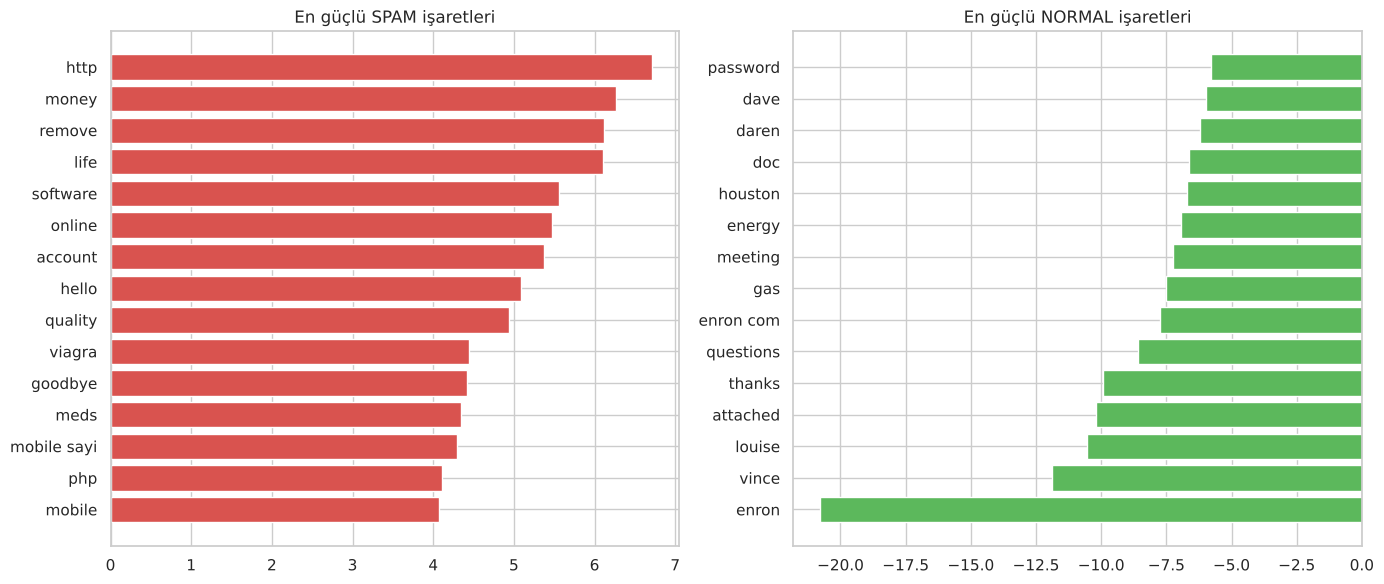

In [15]:
lr = modeller["Lojistik Regresyon"]
kelimeler = np.array(tfidf.get_feature_names_out())
agirlik = lr.coef_[0]
sira = np.argsort(agirlik)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
a1.barh(kelimeler[sira[-15:]], agirlik[sira[-15:]], color="#d9534f"); a1.set_title("En güçlü SPAM işaretleri")
a2.barh(kelimeler[sira[:15]], agirlik[sira[:15]], color="#5cb85c");  a2.set_title("En güçlü NORMAL işaretleri")
plt.tight_layout(); plt.show()

Normal tarafta "enron", "vince", "louise", "houston" gibi şirkete ve çalışanlara özgü kelimeler çıkması beklenen bir durum: Model, şirket içi yazışmaları tanımayı öğrenmiş. Bu aynı zamanda bir **sınırlılık**tır: Bu model Enron dışındaki bir şirketin e-postalarında biraz daha düşük başarı gösterebilir.

## 1️⃣5️⃣ Kendi e-postanla dene 🎯

En iyi modeli kullanarak yeni (İngilizce) e-postaları sınıflandıralım. Aşağıdaki listeye istediğin metni ekleyebilirsin.

In [16]:
yeni_epostalar = [
    "Congratulations! You have won a $1000 Walmart gift card. Click here to claim your prize now!",
    "Hi team, please find attached the agenda for tomorrow's meeting at 10am.",
    "URGENT: Your account has been suspended. Verify your password immediately at this link.",
    "Can you send me the report by Friday? Thanks, John",
]
model = modeller[en_iyi]
vek = tfidf.transform([temizle(e) for e in yeni_epostalar])
for e, t in zip(yeni_epostalar, model.predict(vek)):
    print(("🚫 SPAM  " if t == 1 else "✅ NORMAL") + " | " + e[:80])

🚫 SPAM   | Congratulations! You have won a $1000 Walmart gift card. Click here to claim you
✅ NORMAL | Hi team, please find attached the agenda for tomorrow's meeting at 10am.
🚫 SPAM   | URGENT: Your account has been suspended. Verify your password immediately at thi
✅ NORMAL | Can you send me the report by Friday? Thanks, John


## 📝 Sonuç ve Değerlendirme

**Yapılanlar:**
1. **Veri seti:** 33.716 gerçek e-postadan oluşan, dengeli **Enron-Spam** veri seti kullanıldı.
2. **Ön işleme:** Eksik değerler dolduruldu, konu ve gövde birleştirildi, metin küçük harfe çevrildi; URL, e-posta adresi ve sayılar ortak işaretlere dönüştürüldü.
3. **Özellik çıkarımı:** Metinler **TF-IDF** (tek ve ikili kelime grupları, 30.000 özellik) ile sayısal vektörlere çevrildi.
4. **Modeller:** Naive Bayes, Lojistik Regresyon, Doğrusal SVM ve Random Forest eğitildi.
5. **Test:** %80 eğitim / %20 test bölmesi; Accuracy, Precision, Recall, F1, karışıklık matrisi, ROC-AUC ve 5-katlı çapraz doğrulama ile değerlendirildi.

**Bulgular:** Sonuç tablosunda görüldüğü gibi, metin sınıflandırmada **doğrusal modeller** (SVM ve Lojistik Regresyon) en yüksek başarıyı verdi. Bunun sebebi, TF-IDF'in ürettiği çok sayıda seyrek özellik arasında spam ve normal e-postaları ayıran sınırın büyük ölçüde doğrusal olmasıdır. Naive Bayes çok hızlı ve yine çok başarılı; Random Forest ise bu tür yüksek boyutlu seyrek verilerde hem daha yavaş hem biraz daha geride kaldı.

**Karışıklık matrisi** her modelin hangi tür hatayı (normal maili spam sanma ya da spam kaçırma) ne kadar yaptığını gösterdi. **ROC eğrileri** ve **AUC** değerleri ise modelleri eşik değerinden bağımsız olarak karşılaştırmamızı sağladı; bütün modeller rastgele tahminin (AUC = 0,5) çok üzerinde, 1'e yakın AUC değerleri elde etti.

**Sınırlılıklar ve geliştirme fikirleri:**
- Veri seti İngilizce ve 2000'li yıllara ait; günümüz spam türlerinde (ör. oltalama / phishing) ve Türkçe e-postalarda başarı düşebilir.
- Hiperparametre arama (`GridSearchCV`) ile modeller biraz daha iyileştirilebilir.
- Derin öğrenme tabanlı modeller (LSTM, BERT) kelimelerin bağlamını da anlayarak daha ileri bir çözüm sunabilir.